# Airbnb Madrid: clasificación del tipo de alojamiento y predicción del precio con SVM

El objetivo de este análisis es analizar los datos de Airbnb en Madrid utilizando Máquinas de Vectores de Soporte (SVM), un conjunto de modelos de aprendizaje supervisado aplicados tanto a problemas de clasificación como de regresión.

Las SVM buscan un hiperplano que separe de la mejor manera posible las diferentes clases de datos. Para ello, intentan maximizar la distancia entre los ejemplos más cercanos de cada clase, lo que ayuda a que el modelo generalice mejor a nuevos datos. Además, las SVM pueden manejar casos en los que las clases no se pueden separar con una línea.

Se abordan dos tipos de análisis:

*   **Clasificación**: se busca predecir el tipo de alojamiento a partir del resto de características. Este es un problema de clasificación multiclase para el cual se emplearán LinearSVC, que permite modelar relaciones lineales, y SVC, que captura relaciones no lineales. Los modelos se evaluarán inicialmente mediante validación cruzada y después, se realizará la afinación de hiperparámetros para SVC, ajustando C y gamma.

*  **Regresión**: se pretende predecir el precio por noche de los alojamientos a partir de todas las demás variables. Para ello se utilizarán LinearSVR y SVR. El modelo con mejor rendimiento será afinado ajustando sus hiperparámetros.

Los modelos serán comparados mediante validación cruzada y finalmente se analizará su rendimiento en un conjunto de test, lo que permitirá identificar qué modelo ofrece la mejor predicción tanto para clasificación como para regresión.

**1. LIBRERÍAS**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import RobustScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC, SVC, LinearSVR, SVR
from sklearn.metrics import confusion_matrix, accuracy_score, r2_score, mean_squared_error

**2. CARGA DE LOS DATOS**

In [2]:
alquileres = pd.read_csv('data/airbnb.csv')

**3. EXPLORACIÓN INICIAL Y ANÁLISIS DESCRIPTIVO DE LAS VARIABLES**

Una vez cargados los datos, es importante examinarlos y entender qué tipo de variables y problemas existen en ellos para identificar aspectos relevantes a tener en cuenta después. Para ello, se realiza un breve análisis exploratorio de los datos.

In [3]:
alquileres.head()

,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365
0,Centro,Justicia,40.424715,-3.698638,Entire home/apt,49,28,35,0.42,1,99
1,Centro,Embajadores,40.413418,-3.706838,Entire home/apt,80,5,18,0.30,1,188
2,Moncloa - Aravaca,Argüelles,40.424920,-3.713446,Entire home/apt,40,2,21,0.25,9,195
3,Moncloa - Aravaca,Casa de Campo,40.431027,-3.724586,Entire home/apt,55,2,3,0.13,9,334
4,Latina,Cármenes,40.403410,-3.740842,Private room,16,2,23,0.76,2,250


Cada fila representa una oferta de alquiler y en total tenemos información acerca de 11 variables, que contienen la siguiente información:


*   *neighbourhood_group* : distrito en el que se ubica el alojamiento
*   *neighbourhood* : barrio en el que se ubica el alojamiento
*   *latitude* : latitud del alojamiento
*   *longitude* : longitud del alojamiento
*   *room_type* : tipo de habitación
*   *price* : precio por noche
*   *minimum_nights* : mínimo de noches
*   *number_of_reviews* : número de reseñas
*   *reviews_per_month* : reseñas por mes
*   *calculated_host_listings_count* : número de propiedades del anfitrión
*   *availability_365* : disponibilidad del alojamiento (en días) en 1 año

In [4]:
alquileres.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13321 entries, 0 to 13320
Data columns (total 11 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   neighbourhood_group             13321 non-null  object 
 1   neighbourhood                   13321 non-null  object 
 2   latitude                        13321 non-null  float64
 3   longitude                       13321 non-null  float64
 4   room_type                       13321 non-null  object 
 5   price                           13321 non-null  int64  
 6   minimum_nights                  13321 non-null  int64  
 7   number_of_reviews               13321 non-null  int64  
 8   reviews_per_month               13321 non-null  float64
 9   calculated_host_listings_count  13321 non-null  int64  
 10  availability_365                13321 non-null  int64  
dtypes: float64(3), int64(5), object(3)
memory usage: 1.1+ MB


Observamos que hay un total de 13321 ofertas y que ninguna de las 11 variables presenta valores nulos. Además, de estas 11 variables, 8 son numéricas y 3 son categóricas.

**Variables numéricas**

En las siguientes celdas se visualiza un resumen de diferentes medidas estadísticas de las variables numéricas junto con sus histogramas.

In [5]:
alquileres.describe()

,latitude,longitude,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365
count,13321.000000,13321.000000,13321.000000,13321.000000,13321.000000,13321.000000,13321.000000,13321.000000
mean,40.420730,-3.697268,69.171834,3.010885,22.986037,1.520329,7.605885,205.867202
std,0.020344,0.023832,103.721126,12.835619,38.406006,1.852367,19.619972,126.968961
min,40.331888,-3.863907,9.000000,1.000000,0.000000,0.000000,1.000000,0.000000
25%,40.410090,-3.707856,31.000000,1.000000,1.000000,0.110000,1.000000,84.000000
50%,40.418731,-3.701602,53.000000,2.000000,7.000000,0.780000,2.000000,247.000000
75%,40.427997,-3.693818,80.000000,3.000000,28.000000,2.320000,4.000000,321.000000
max,40.562736,-3.526821,7700.000000,1125.000000,446.000000,17.210000,145.000000,365.000000


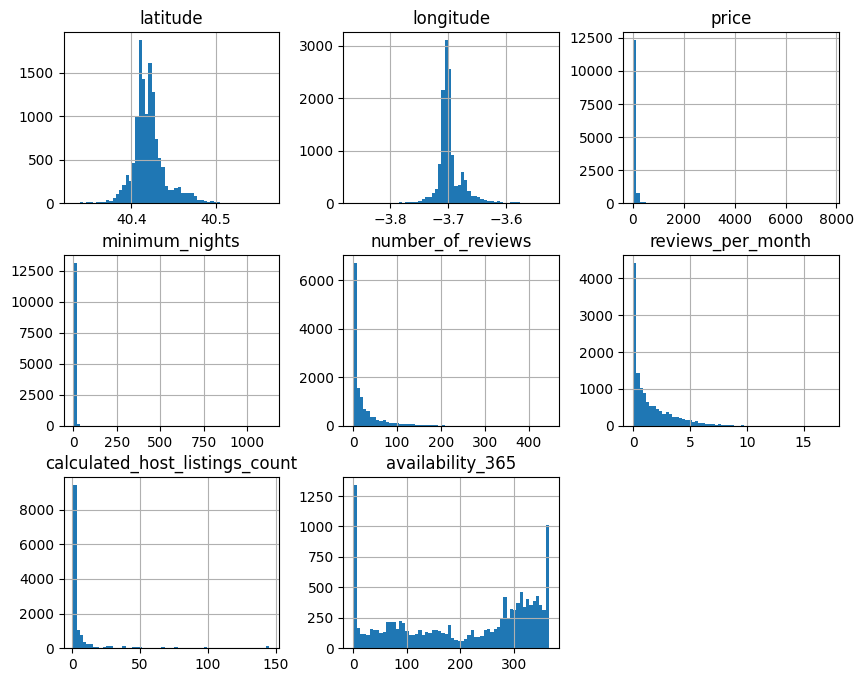

In [6]:
alquileres.hist(bins=60, figsize=(10, 8))
plt.show()

Las variables *latitude* y *longitude* se distribuyen de forma aproximadamente simétrica, con una dispersión muy baja, indicando que los alojamientos se concentran en una misma zona.

En cambio, las variables *price*, *minimum_nights*, *number_of_reviews*, *reviews_per_month* y *calculated_host_listings_count* muestran histogramas con distribuciones asimétricas positivas (reflejado en la diferencia existente entre la media y la mediana) y tienen alta dispersión, con gran parte de los valores cerca de 0. En todas ellas se observan valores atípicos/outliers, ya que los valores máximos están muy alejados del percentil 75.

Por último, en *availability_365* se observan 2 modas (picos) en los extremos, indicando que gran parte de los alojamientos no están disponibles durante todo el año o están disponibles la mayor parte del tiempo.


Otro aspecto a destacar es que las variables se miden en escalas numéricas muy diferentes (por ejemplo, *price* en €, *minimum_nights* en días, etc), por lo que será necesario aplicar algún tipo de escalado más adelante.

**Variables categóricas**

A continuación, examinamos los recuentos de cada clase de las tres variables categóricas.

In [7]:
alquileres["room_type"].value_counts()

,count
room_type,
Entire home/apt,7926
Private room,5203
Shared room,192


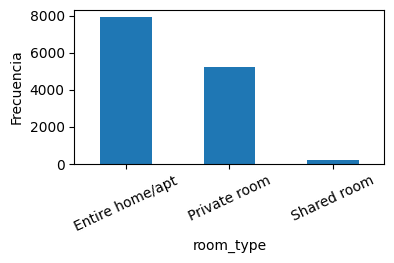

In [8]:
plt.figure(figsize=(4,2))
alquileres['room_type'].value_counts().plot(kind='bar')

plt.ylabel('Frecuencia')
plt.xticks(rotation=25)
plt.show()

La variable *room_type* presenta tres categorías: Entire home/apt (7926 filas), Private room (5203) y Shared room (192).

Se aprecia un desbalance entre las categorías, ya que la mayoría de las ofertas son de apartamentos enteros, mientras que las habitaciones compartidas son muy poco frecuentes. Esta característica habrá que tenerla en cuenta en la creación de los modelos de clasificación.

In [9]:
alquileres["neighbourhood_group"].value_counts()

,count
neighbourhood_group,
Centro,6773
Chamberí,960
Salamanca,883
Arganzuela,790
Tetuán,463
Moncloa - Aravaca,450
Retiro,439
Latina,379
Chamartín,361


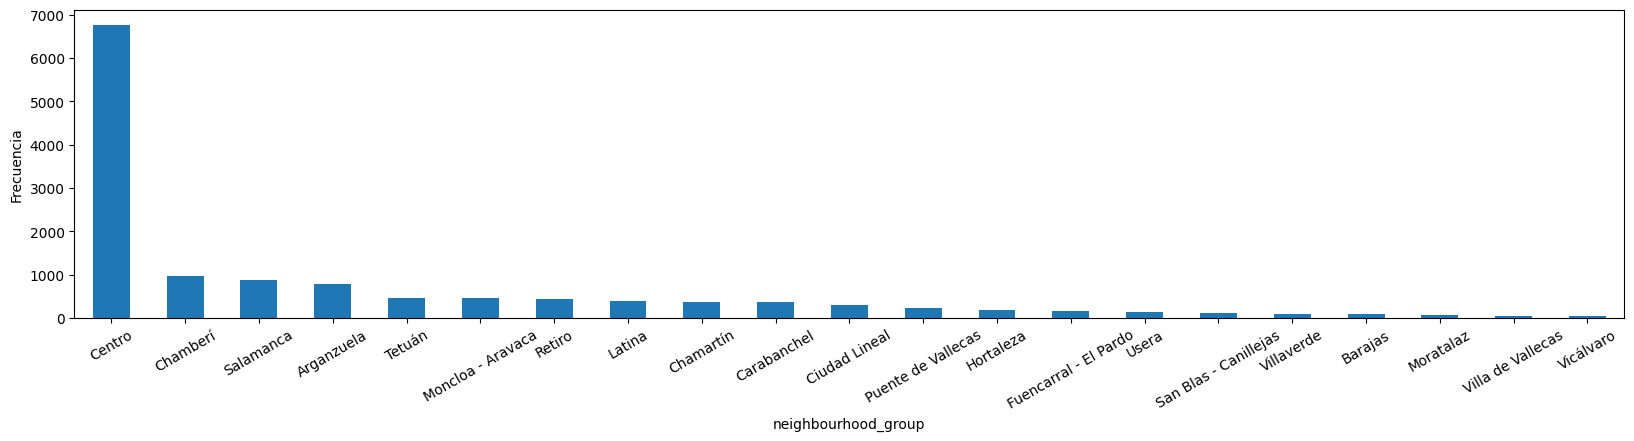

In [10]:
plt.figure(figsize=(20,4))
alquileres['neighbourhood_group'].value_counts().plot(kind='bar')
plt.ylabel('Frecuencia')
plt.xticks(rotation=30)
plt.show()

In [11]:
alquileres["neighbourhood"].value_counts()

,count
neighbourhood,
Embajadores,1848
Universidad,1363
Palacio,1084
Sol,942
Justicia,788
...,...
El Goloso,4
Pavones,4
Cuatro Vientos,3


Tanto en *neighbourhood* como en *neighbourhood_group* se deja ver que en el distrito Centro y en los barrios pertenecientes a este distrito (Embajadores, Universidad, Palacio, Sol, Justicia), se concentran las ofertas de alquiler mayoritariamente.

El resto de distritos y barrios presentan mucha menor proporción de ofertas e incluso en barrios como Orcasitas o El Pardo apenas hay ofertas.

Esta distribución tiene sentido al tratarse de apartamentos turísticos, ya que en el distrito Centro se concentra la mayor parte de los puntos de interés y las ofertas de alojamientos se ubican en él principalmente.

**Valores atípicos/outliers**

En los histogramas hemos detectado posibles outliers, por lo que vamos a dibujar diagramas de caja (boxplots) para detectar las observaciones que se alejan del rango intercuartílico (IQR=Q3-Q1).

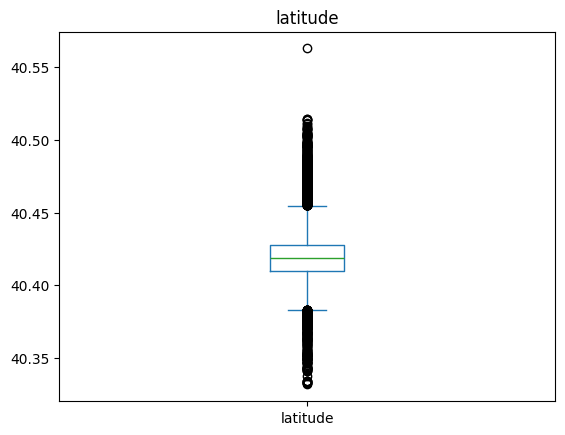

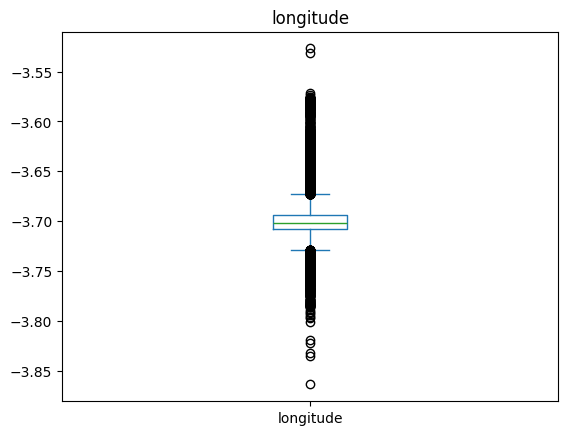

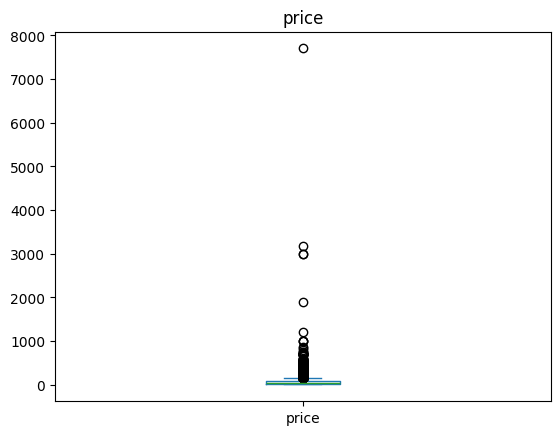

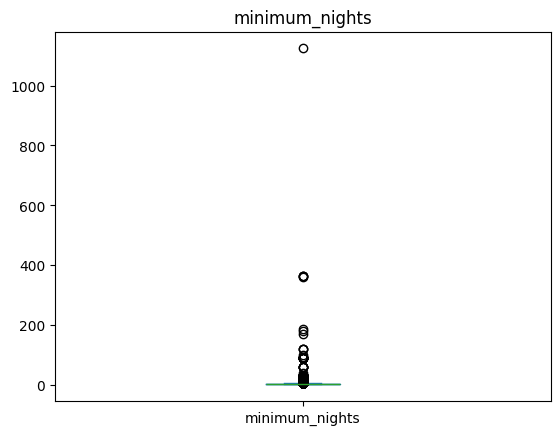

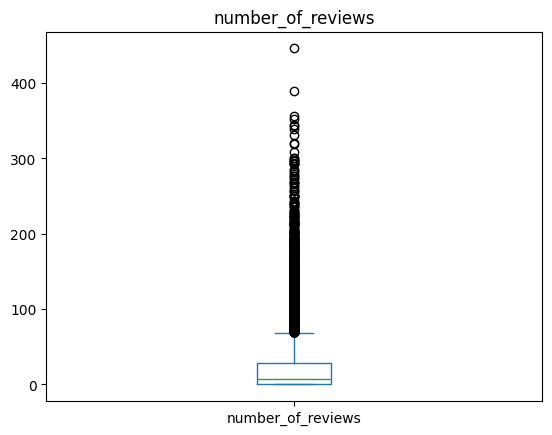

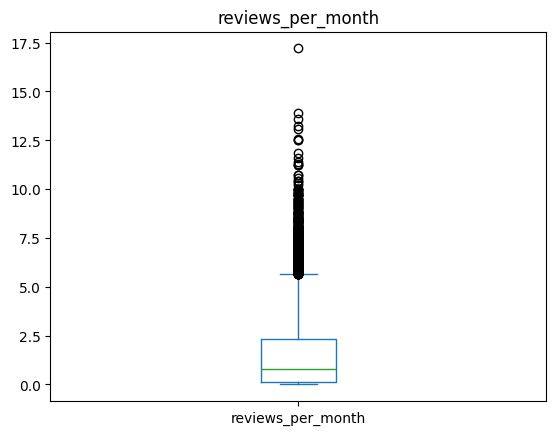

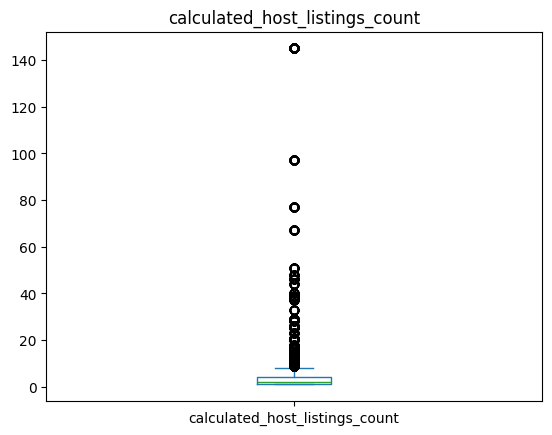

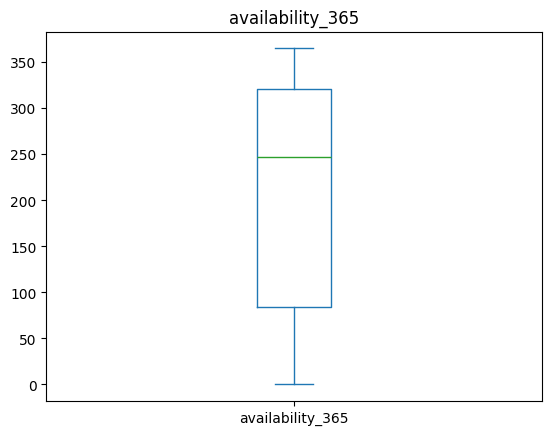

In [12]:
numeric_cols = ['latitude', 'longitude', 'price', 'minimum_nights', 'number_of_reviews', 'reviews_per_month',
                'calculated_host_listings_count', 'availability_365']

for col in numeric_cols:
    if col in alquileres.columns:
        plt.figure()
        alquileres[col].plot.box()
        plt.title(col)
        plt.show()

Las variables *latitude* y *longitude* muestran algunos valores fuera del rango intercuartílico debido a que la mayoría de los alojamientos se concentran en el centro de Madrid. Estos son valores correspondientes a zonas alejadas, pero no se consideran errores.

Las variables *price*, *minimum_nights*, *number_of_reviews*, *reviews_per_month* y *calculated_host_listings_count* presentan distribuciones muy sesgadas. Aplicaremos transformaciones logarítmicas para intentar corregir este sesgo.

Además, se eliminarán los valores extremos de *price* (> 2000 €/noche) y *minimum_nights* (> 365 noches), que son poco realistas. En cambio, los outliers de *number_of_reviews*, *reviews_per_month* y *calculated_host_listings_count* se mantienen, ya que pueden reflejar casos válidos. La variable *availability_365* no presenta valores atípicos significativos.

En las siguientes celdas eliminamos los extremos comentados de *price* y *minimum_nigths*, a la vez que realizamos transformaciones logarítmicas a las variables que están sesgadas.
Para *number_of_reviews* y *reviews_per_month* aplicamos el logaritmo del valor de la variable + 1 (log1p), ya que observando el resumen de medidas estadísticas vemos que hay valores 0 y no existe el logaritmo de 0. Para el resto de variables no haría falta al no haber ceros.

In [13]:
alquileres = alquileres[alquileres['price'] <= 2000]
alquileres = alquileres[alquileres['minimum_nights'] <= 365]

In [14]:
alquileres['log_price'] = np.log(alquileres['price'])
alquileres['log_minimum_nights'] = np.log(alquileres['minimum_nights'])
alquileres['log_number_of_reviews'] = np.log1p(alquileres['number_of_reviews'])
alquileres['log_reviews_per_month'] = np.log1p(alquileres['reviews_per_month'])
alquileres['log_calculated_host_listings_count'] = np.log(alquileres['calculated_host_listings_count'])

Observamos cómo se distribuyen las variables tras aplicar las transformaciones:

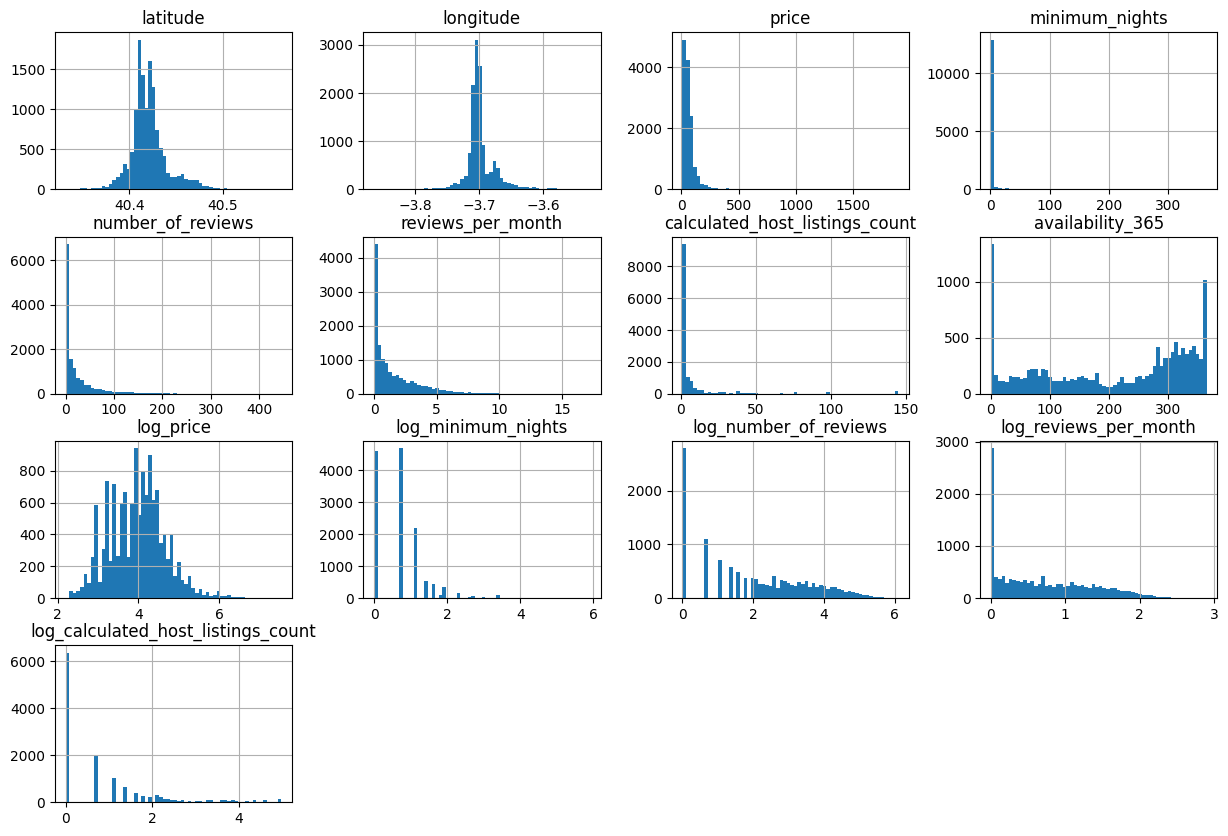

In [15]:
alquileres.hist(bins=60, figsize=(15, 10))
plt.show()

En el histograma de *log_price* se observa que la transformación logarítmica ha sido muy efectiva, ya que se consigue mejorar significativamente la simetría de la distribución, aproximándola a una normal. Sin embargo, el resto de variables siguen estando bastante sesgadas, debido a la gran concentración de valores muy bajos.

**Correlaciones entre variables**

Para ver las posibles relaciones entre las variables vamos a calcular la matriz de correlaciones y a visualizar algunos gráficos de dispersión de las variables que pueden estar más relacionadas entre sí.

In [16]:
numeric_cols_con_log = ['latitude', 'longitude','log_price', 'log_minimum_nights', 'log_number_of_reviews',
            'log_reviews_per_month', 'log_calculated_host_listings_count', 'availability_365']

corr_matrix = alquileres[numeric_cols_con_log].corr()

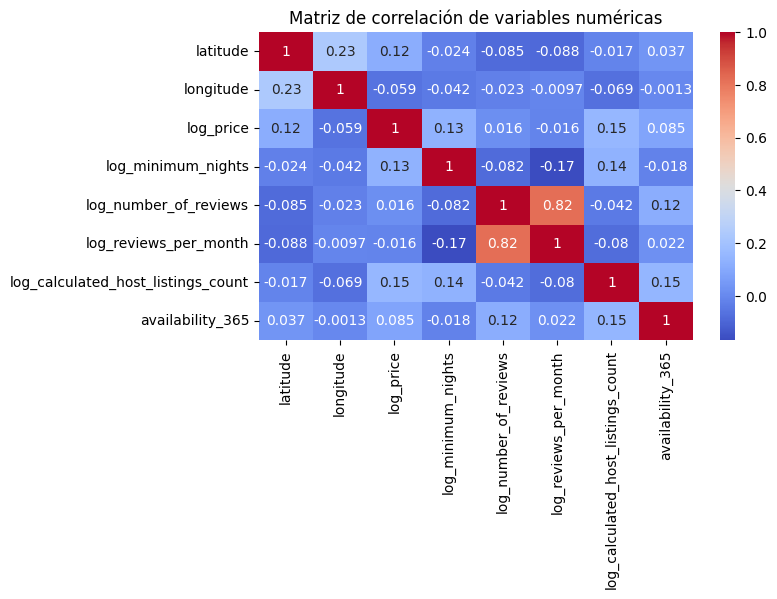

In [17]:
plt.figure(figsize=(7,4))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm')
plt.title("Matriz de correlación de variables numéricas")
plt.show()


Los valores cercanos a 1 o -1 indican correlaciones fuertes, mientras que los cercanos a 0 reflejan ausencia de relación lineal.

Se observa que la mayor correlación positiva se da entre *log_number_of_reviews* y *log_reviews_per_month* (0.82), lo cual es esperable al ser información redundante.

También hay otras correlaciones más débiles:

*  *latitude* y *longitude* : 0.23 (moderada)

*  *log_calculated_host_listings_count* y *availability_365*, *log_price* y *log_minimum_nights* : 0.12-0.15

*  *log_minimum_nights* y *log_reviews_per_month* : -0.17 (débil negativa)


En general, las variables muestran correlaciones bajas, siendo la más significativa la redundancia entre reseñas totales y por mes.

A continuación se presentan gráficos de dispersión y de barras para observar las relaciones entre diferentes variables con *room_type* y con *log_price*.


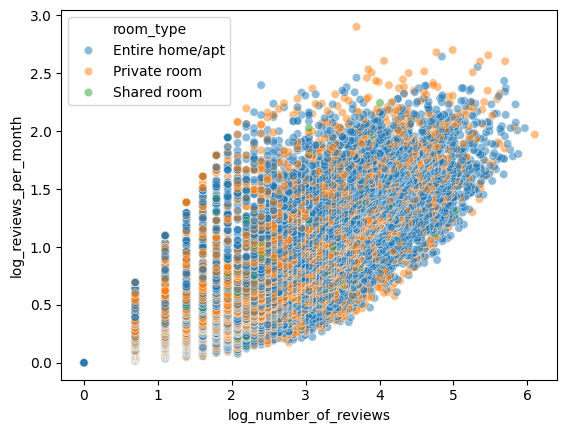

In [18]:
sns.scatterplot(data=alquileres, x='log_number_of_reviews', y='log_reviews_per_month', hue='room_type', alpha=0.5)
plt.show()

Como ya hemos visto en la matriz de correlación, *log_number_of_reviews* y *log_reviews_per_month* tienen una relación lineal muy fuerte. También se aprecia que predominan los apartamentos enteros (puntos azules), mientras que las habitaciones privadas aparecen en menor proporción (puntos naranjas) y las habitaciones compartidas (puntos verdes) apenas se dejan ver.

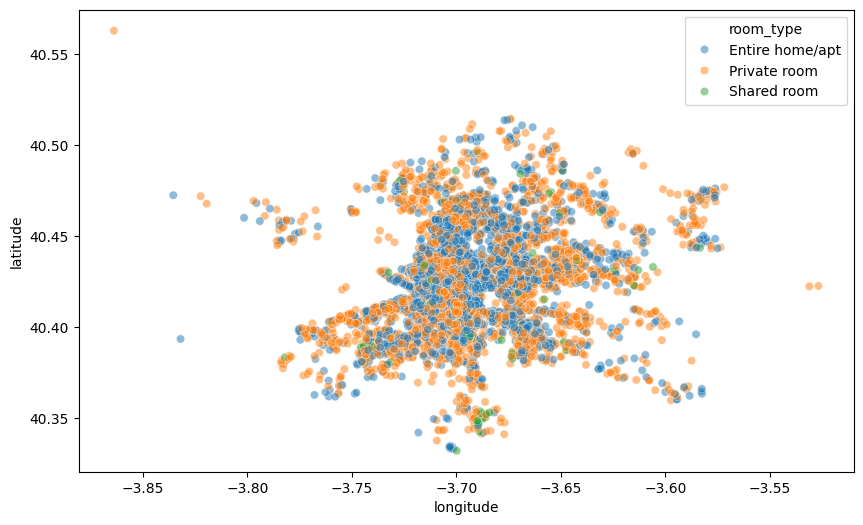

In [19]:
plt.figure(figsize=(10,6))
sns.scatterplot(data=alquileres, x='longitude', y='latitude', hue='room_type', alpha=0.5)
plt.show()

Al representar la *latitude* frente a la *longitude* obtenemos una especie de mapa donde vemos la ubicación de los diferentes tipos de habitaciones. Se aprecia que en el centro hay mayor proporción de ofertas de apartamentos completos (puntos azules), mientras que las habitaciones privadas (puntos naranjas) se concentran más a las afueras. Las habitaciones compartidas (puntos verdes) están más dispersas y también se ven muy pocas.

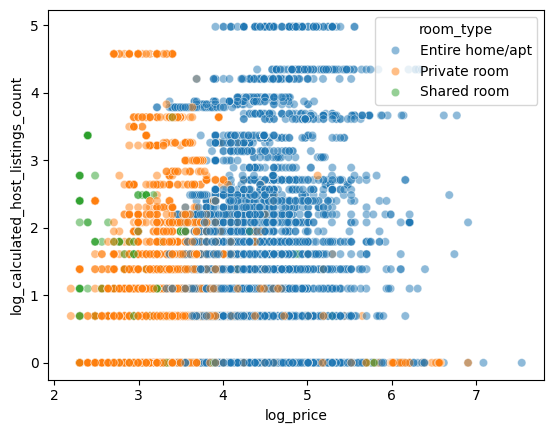

In [20]:
sns.scatterplot(data=alquileres, x='log_price', y='log_calculated_host_listings_count', hue='room_type', alpha=0.5)
plt.show()

La dispersión entre *log_price* y *log_calculated_host_listings_count* es muy grande. Además, se aprecia que los apartamentos enteros predominan en los precios más altos y en los anfitriones con más propiedades, mientras que las habitaciones privadas tienen precios más bajos y sus anfitriones no tienen tantas propiedades. También se aprecia que los precios más bajos son los de las habitaciones compartidas.

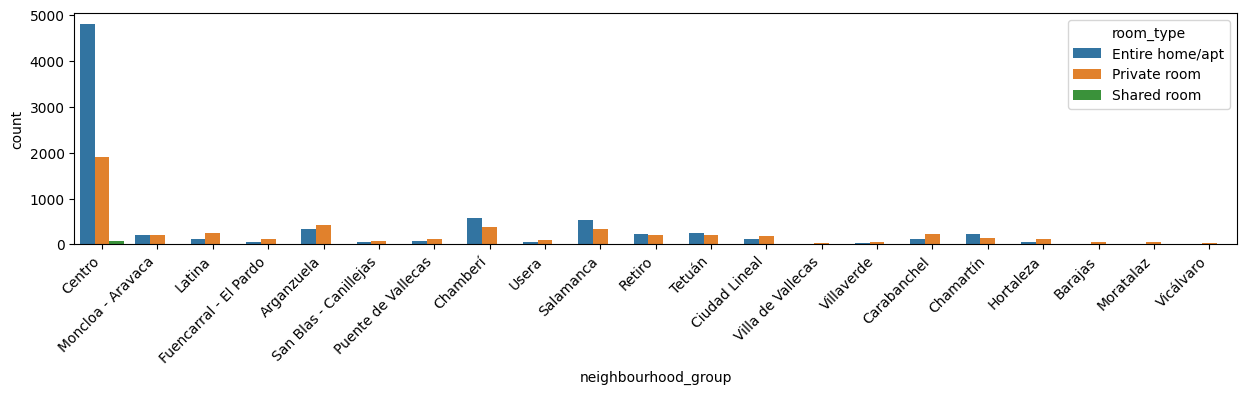

In [21]:
plt.figure(figsize=(15,3))
sns.countplot(data=alquileres, x='neighbourhood_group', hue='room_type')
plt.xticks(rotation=45, ha='right')
plt.show()

Como ya hemos visto la gran mayoría de alojamientos se ubican en el distrito Centro, destacando la categoría de apartamento entero, y en menor medida habitación privada. Además, es el único distrito que tiene ofertas de habitaciones compartidas, aunque muy pocas.

<Axes: xlabel='log_price', ylabel='Count'>

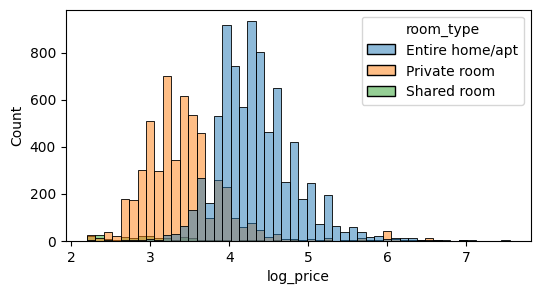

In [22]:
plt.figure(figsize=(6,3))
sns.histplot(data=alquileres, x='log_price', hue='room_type', bins=50, alpha=0.5)

Se observa que los apartamentos enteros (azul) tienen precios más altos, mientras que las habitaciones privadas (naranja) tienen precios más bajos. Las habitaciones compartidas representan la categoría con precios más bajos.

Por tanto, el precio parece diferenciar bien los tipos de alojamiento, por lo que será una variable relevante en el modelo de clasificación. De manera inversa, el tipo de alojamiento está relacionado con el precio, por lo que aportará información significativa en el modelo de regresión al predecir el precio por noche.

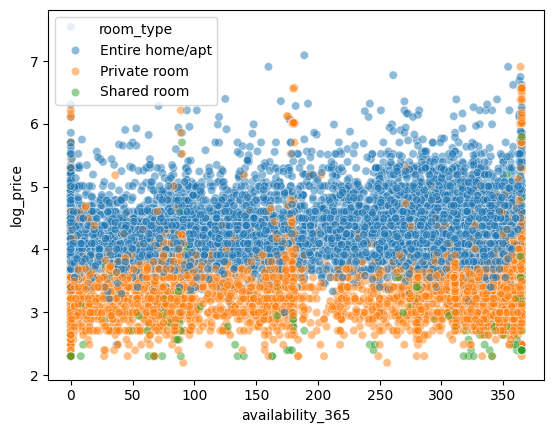

In [23]:
sns.scatterplot(data=alquileres, x='availability_365', y='log_price', hue='room_type', alpha=0.5)
plt.show()

De nuevo se observa que los apartamentos enteros tienden a tener precios más altos, mientras que las habitaciones privadas presentan precios intermedios y las compartidas son las más económicas. En cuanto a la disponibilidad, no parece haber una relación clara entre días disponibles y precio, ya que los puntos están bastante dispersos.

Antes de realizar la división de datos, nos quedamos con las variables que vamos a usar, es decir, las categóricas y las numéricas transformadas:

In [24]:
variables_def = ['latitude', 'longitude','log_price', 'log_minimum_nights', 'log_number_of_reviews',
            'log_reviews_per_month', 'log_calculated_host_listings_count', 'availability_365', 'neighbourhood', 'neighbourhood_group', 'room_type']

In [25]:
alquileres = alquileres[variables_def]

**4. DIVISÓN DE LOS DATOS EN ENTRENAMIENTO Y PRUEBA**

Dividimos el conjunto de datos en entrenamiento y prueba, asignando un 80 % de los datos al conjunto de entrenamiento y un 20 % al conjunto de prueba. Con random_state fijamos una semilla y con stratify indicamos que en los dos conjuntos asigne la misma proporción de clases de *room_type*, ya que al estar desbalanceada algunas categorías podrían quedar desproporcionadas.

In [26]:
alquileres_train, alquileres_test = train_test_split(alquileres, test_size=0.2, random_state=42, stratify = alquileres["room_type"])

In [27]:
len(alquileres_train)

10652

In [28]:
len(alquileres_test)

2664

Del total de 13321 filas, 10652 se han asignado al conjunto de entrenamiento y 2664 al conjunto de prueba.

Separamos los datos de las variables explicativas de los datos de la variable objetivo, tanto en el conjunto de entrenamiento como en el de prueba:



*   Clasificación


In [29]:
X_train_clf = alquileres_train.drop('room_type', axis=1)
y_train_clf = alquileres_train['room_type']

X_test_clf = alquileres_test.drop('room_type', axis=1)
y_test_clf = alquileres_test['room_type']



*   Regresión



In [30]:
X_train_reg = alquileres_train.drop('log_price', axis=1)
y_train_reg = alquileres_train['log_price']

X_test_reg = alquileres_test.drop('log_price', axis=1)
y_test_reg = alquileres_test['log_price']

**5. CLASIFICACIÓN**

En este apartado se realizará la clasificación multiclase de la variable *room_type* mediante LinearSVC y SVC.
La variable dependiente será *room_type*, y las variables independientes el resto de características disponibles.
La variable *neighbourhood* se ha excluido, ya que aporta información redundante al estar presentes *neighbourhood_group* y las coordenadas *latitude* y *longitude*, evitando la creación de demasiadas columnas al aplicar OneHotEncoder.

El preprocesamiento incluye el uso de RobustScaler para las variables numéricas, para intentar reducir el efecto de los valores atípicos, y OneHotEncoder para *neighbourhood_group*.

Finalmente, la evaluación de los modelos se realizará mediante validación cruzada, utilizando la métrica de accuracy para comparar su desempeño.


In [31]:
categorical_clf = ['neighbourhood_group']
numeric_clf = ['latitude', 'longitude', 'log_price', 'log_minimum_nights', 'log_number_of_reviews',
                'log_reviews_per_month', 'log_calculated_host_listings_count', 'availability_365']

preprocessor_clf = ColumnTransformer(transformers=[
    ('num', RobustScaler(), numeric_clf),
    ('cat', OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore'), categorical_clf)
])

**5.1. LinearSVC**

Se crea un modelo LinearSVC para abordar la clasificación de *room_type*, incorporando el preprocesamiento de variables en un pipeline.
Para compensar los desbalances entre clases, se utiliza el parámetro class_weight='balanced'.
El modelo emplea el valor por defecto de regularización C=1, que controla el equilibrio entre ajuste a los datos y capacidad de generalización. La evaluación se realiza mediante validación cruzada con 10 particiones.

In [32]:
pipe_linear_svc = Pipeline([
    ('preprocess', preprocessor_clf),
    ('model', LinearSVC(random_state=42, class_weight='balanced'))
])

In [33]:
scores_linear = cross_val_score(
    pipe_linear_svc,
    X_train_clf,
    y_train_clf,
    cv=10,
    scoring='accuracy'
)

scores_linear.mean()

np.float64(0.8727928546891104)

La media de accuracy obtenida mediante validación cruzada con 10 particiones es de 0.8728, lo que indica que el modelo predice correctamente el tipo de alojamiento en aproximadamente el 87.3% de las observaciones.

**5.2. SVC**

Para ver si considerando un modelo no lineal mejoran los resultados, se crea un modelo SVC.

De nuevo se utilizan los valores por defecto para todos los parámetros, excepto class_weight='balanced'. Por defecto, SVC utiliza un kernel RBF (kernel='rbf') para capturar relaciones no lineales, C=1 como parámetro de regularización y gamma='scale', que indica que el modelo ajustará la influencia de cada dato en función de la varianza y el número de características.

In [34]:
pipeline_svc = Pipeline([
    ('preprocess', preprocessor_clf),
    ('model', SVC(class_weight='balanced'))
])

In [35]:
scores_svc = cross_val_score(
    pipeline_svc,
    X_train_clf,
    y_train_clf,
    cv=10,
    scoring='accuracy'
)
scores_svc.mean()

np.float64(0.8493236089457319)

Con SVC, la media de exactitud obtenida mediante validación cruzada es del 84.93%, ligeramente inferior a la obtenida con LinearSVC (87.28%), lo que indica que LinearSVC predice ligeramente mejor el tipo de alojamiento en validación.

**5.3. Afinación de hiperparámetros (SVC)**

En este apartado se realiza la afinación de los hiperparámetros de SVC, concretamente C y gamma, usando el kernel RBF mediante GridSearchCV. Primero se hace una búsqueda amplia y después una búsqueda más refinada alrededor de los mejores valores encontrados en la anterior búsqueda.

**Primera búsqueda**

Se realiza una primera búsqueda de hiperparámetros en escalas logarítmicas amplias mediante GridSearchCV con 3 particiones de validación cruzada.
Cada combinación de los parámetros C y gamma se entrena y evalúa, y se selecciona aquella que maximiza la métrica (en este caso accuracy) promedio.

In [36]:
param_grid1 = {
    'model__C': np.logspace(-2, 3, 6),
    'model__gamma': np.logspace(-4, 1, 6)
}

grid1 = GridSearchCV(
    pipeline_svc,
    param_grid1,
    cv=3,
    scoring='accuracy',
    n_jobs=-1
)

grid1.fit(X_train_clf, y_train_clf)

GridSearchCV(cv=3,
             estimator=Pipeline(steps=[('preprocess',
                                        ColumnTransformer(transformers=[('num',
                                                                         RobustScaler(),
                                                                         ['latitude',
                                                                          'longitude',
                                                                          'log_price',
                                                                          'log_minimum_nights',
                                                                          'log_number_of_reviews',
                                                                          'log_reviews_per_month',
                                                                          'log_calculated_host_listings_count',
                                                                          'availability_365']),
                                                                        ('cat',
                                                                         OneHotEncoder(drop='first',
                                                                                       handle_unknown='ignore',
                                                                                       sparse_output=False),
                                                                         ['neighbourhood_group'])])),
                                       ('model',
                                        SVC(class_weight='balanced'))]),
             n_jobs=-1,
             param_grid={'model__C': array([1.e-02, 1.e-01, 1.e+00, 1.e+01, 1.e+02, 1.e+03]),
                         'model__gamma': array([1.e-04, 1.e-03, 1.e-02, 1.e-01, 1.e+00, 1.e+01])},
             scoring='accuracy')

**Segunda búsqueda**

A continuación, se realiza una segunda búsqueda más refinada alrededor de los valores óptimos obtenidos en la primera búsqueda.
Se definen rangos estrechos para C y gamma y se aplica nuevamente GridSearchCV con 3 particiones de validación cruzada.
La combinación de parámetros que maximiza accuracy será la configuración final del modelo.

In [37]:
best_C = grid1.best_params_['model__C']
best_gamma = grid1.best_params_['model__gamma']

param_grid2 = {
    'model__C': np.logspace(np.log10(best_C/5), np.log10(best_C*5), 5),
    'model__gamma': np.logspace(np.log10(best_gamma/5), np.log10(best_gamma*5), 5)
}

grid2 = GridSearchCV(
    pipeline_svc,
    param_grid2,
    cv=3,
    scoring='accuracy',
    n_jobs=-1
)

grid2.fit(X_train_clf, y_train_clf)
print("Mejores parámetros fine grid:", grid2.best_params_)


Mejores parámetros fine grid: {'model__C': np.float64(2.0), 'model__gamma': np.float64(1.0)}


La combinación óptima corresponde a C = 2 y gamma = 1, parámetros que maximizan la capacidad para generalizar a datos no vistos.

Se redefine el pipeline con esta configuración y se evalúa de nuevo el modelo con validación cruzada de 10 particiones:

In [41]:
pipeline_svc2 = Pipeline([
    ('preprocess', preprocessor_clf),
    ('model', SVC(C=2, gamma=1, class_weight='balanced', kernel='rbf'))
])

scores_svc2 = cross_val_score(
    pipeline_svc2,
    X_train_clf,
    y_train_clf,
    cv=10,
    scoring='accuracy',

)
scores_svc2.mean()

np.float64(0.885092267174026)

Con SVC ajustado a los parámetros óptimos (C = 2, gamma = 1), el modelo alcanza una exactitud del 88.5%, lo que representa una mejora frente a LinearSVC y SVC con la configuración por defecto.

**5.4. Evaluación final en el conjunto test**

Para evaluar la capacidad de los modelos de predecir sobre datos no vistos, se realiza una evaluación en el conjunto de test.

In [42]:
# Entrenar los modelos
pipe_linear_svc.fit(X_train_clf, y_train_clf)
pipeline_svc.fit(X_train_clf, y_train_clf)
pipeline_svc2.fit(X_train_clf, y_train_clf)

# Predecir en test
y_pred_linear = pipe_linear_svc.predict(X_test_clf)
y_pred_svc = pipeline_svc.predict(X_test_clf)
y_pred_svc2 = pipeline_svc2.predict(X_test_clf)

# Accuracy
acc_linear = accuracy_score(y_test_clf, y_pred_linear)
acc_svc1= accuracy_score(y_test_clf, y_pred_svc)
acc_svc2 = accuracy_score(y_test_clf, y_pred_svc2)

print("Accuracy en test:")
print("LinearSVC:", round(acc_linear, 4))
print("SVC:", round(acc_svc1, 4))
print("SVC afinado:", round(acc_svc2, 4))


Accuracy en test:
LinearSVC: 0.8731
SVC: 0.8457
SVC afinado: 0.89


La evaluación en el conjunto de test muestra que el modelo LinearSVC alcanza una exactitud del 87.31%, mientras que el SVC con los hiperparámetros por defecto logra un 84.57%. Con SVC afinado se logra alcanzar una exactitud del 89%.

Estos resultados indican que el ajuste de los parámetros C y gamma en SVC permite obtener una mejora en la capacidad de generalización del modelo sobre datos no vistos.

Se calculan matrices de confusión para ver cómo se distribuyen las predicciones frente a las clases reales del tipo de alojamiento:

* **LinearSVC**

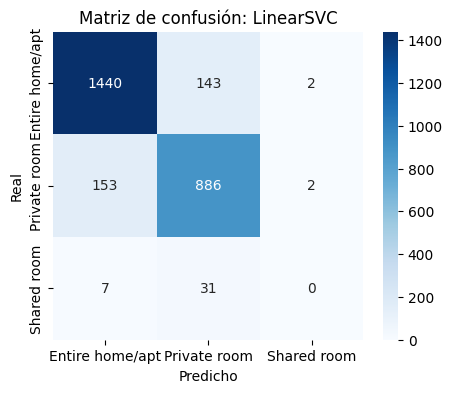

In [43]:
cm_linear = confusion_matrix(y_test_clf, y_pred_linear)
plt.figure(figsize=(5,4))
sns.heatmap(cm_linear, annot=True, fmt='d', cmap='Blues',
            xticklabels=y_test_clf.unique(),
            yticklabels=y_test_clf.unique())
plt.xlabel('Predicho')
plt.ylabel('Real')
plt.title('Matriz de confusión: LinearSVC')
plt.show()


La matriz de confusión del modelo LinearSVC muestra que el modelo predice correctamente la mayoría de las observaciones de las categorías Entire home/apt (1440 aciertos) y Private room (886 aciertos), mientras que en la clase Shared room no acierta ninguna observación, ya que las confunde con Private room (31) y Entire home/apt (7). Esto indica que el modelo es muy eficaz para distinguir entre las dos clases más frecuentes, pero tiene dificultades para identificar correctamente la clase minoritaria.



*   **SVC**



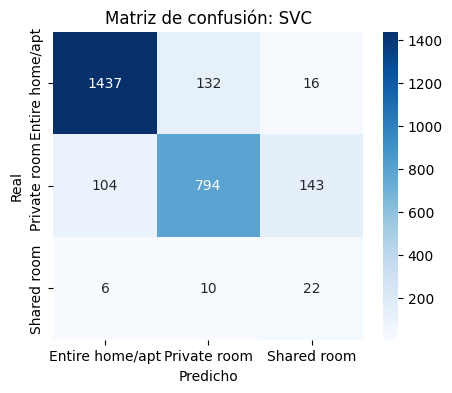

In [44]:
cm_svc = confusion_matrix(y_test_clf, y_pred_svc)
plt.figure(figsize=(5,4))
sns.heatmap(cm_svc, annot=True, fmt='d', cmap='Blues',
            xticklabels=y_test_clf.unique(),
            yticklabels=y_test_clf.unique())
plt.xlabel('Predicho')
plt.ylabel('Real')
plt.title('Matriz de confusión: SVC')
plt.show()

El modelo SVC demuestra una mejor capacidad para identificar observaciones de la categoría "Shared room", logrando 22 aciertos frente a los cero resultados del modelo lineal. Aunque mantiene una alta precisión en la categoría de "Entire home/apt", el uso de relaciones no lineales introduce mayor confusión en "Private room".



*   **SVC refinado**



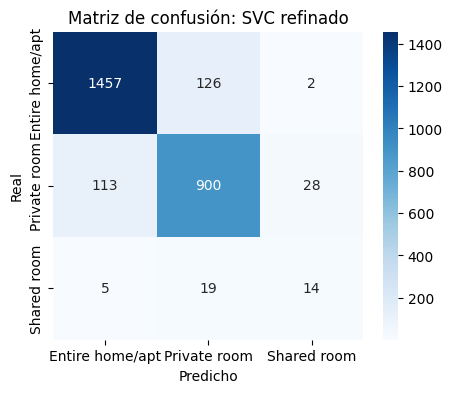

In [45]:
cm_svc2 = confusion_matrix(y_test_clf, y_pred_svc2)
plt.figure(figsize=(5,4))
sns.heatmap(cm_svc2, annot=True, fmt='d', cmap='Blues',
            xticklabels=y_test_clf.unique(),
            yticklabels=y_test_clf.unique())
plt.xlabel('Predicho')
plt.ylabel('Real')
plt.title('Matriz de confusión: SVC refinado')
plt.show()

Se observa que el ajuste de hiperparámetros en SVC ha logrado mejores resultados frente a los anteriores modelos.

Se ve una notable mejora en la clasificación de "Private room", que alcanza su valor más alto con 900 aciertos. Además, mejora ligeramente también la capacidad de clasificar correctamente "Entire home/apt". Aunque la detección de "Shared room" disminuye ligeramente a 14 aciertos respecto a los 22 del SVC sin refinar, el modelo refinado es el que mejor desempeño tiene.

**5.5. Conclusiones de los modelos de clasificación**

In [76]:
datos = {
    "Modelo": ["LinearSVC", "SVC", "SVC afinado"],
    "Accuracy CV (%)": [87.28, 84.93, 88.5],
    "Accuracy Test (%)": [87.31, 84.57, 89]
}

tabla_resultados = pd.DataFrame(datos)
display(tabla_resultados)

,Modelo,Accuracy CV (%),Accuracy Test (%)
0,LinearSVC,87.28,87.31
1,SVC,84.93,84.57
2,SVC afinado,88.50,89.00


En conclusión, LinearSVC alcanza una exactitud de 87.28% en validación cruzada y 87.31% en test, demostrando alta precisión en las clases mayoritarias (“Entire home/apt” y “Private room”) pero sin capacidad para identificar la clase minoritaria (“Shared room”).

SVC con kernel RBF y parámetros por defecto obtiene una exactitud menor (84.93% en validación y 84.57% en test), aunque mejora la detección de “Shared room” gracias a su capacidad de modelar relaciones no lineales.

Tras la afinación de hiperparámetros C y gamma mediante GridSearchCV, SVC alcanza el mejor desempeño, con 88.5% en validación cruzada y 89% en test, aumentando la clasificación correcta de “Private room” y “Entire home/apt”, aunque la detección de “Shared room” disminuye ligeramente.

**6. REGRESIÓN**

En este apartado se aborda un problema de regresión en el que la variable dependiente será *log_price*, obtenida a partir de la transformación logarítmica de *price* para reducir la asimetría. Las variables independientes serán el resto de características disponibles.

Se emplean LinearSVR y SVR como modelos y se evaluarán mediante validación cruzada utilizando el coeficiente de determinación R², que indica la proporción de variabilidad del precio explicada por las variables predictoras.

**6.1. Eliminación de outliers**

En primer lugar realizamos un estudio de outliers de las variables *log_price*, *log_minimun_nights* y *log_calculated_host_listings_count* más exhaustivo que en la exploración inicial y esta vez sobre las variables transformadas, ya que los valores extremos pueden afectar significativamente el entrenamiento de los modelos SVR, que se basan en distancias.

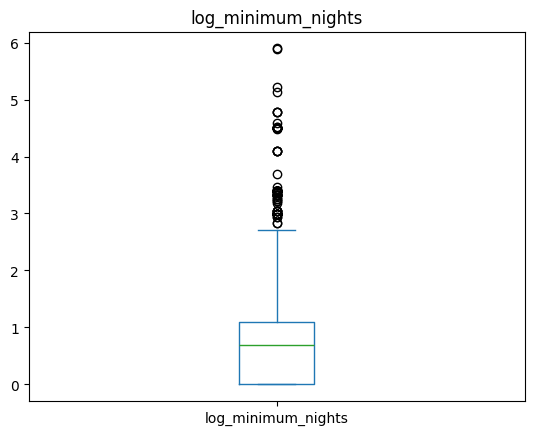

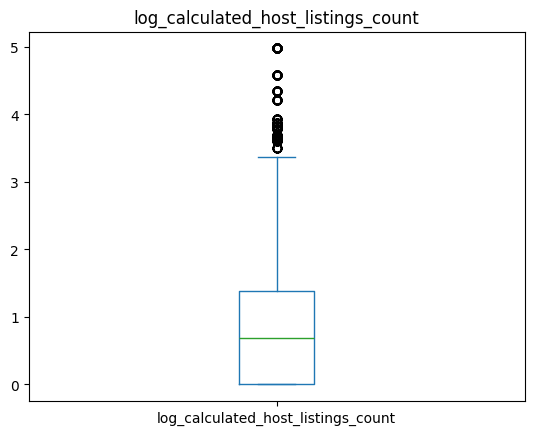

In [46]:
variables_indep = ['log_minimum_nights', 'log_calculated_host_listings_count']

for var in variables_indep:
    if var in X_train_reg.columns:
        plt.figure()
        X_train_reg[var].plot.box()
        plt.title(var)
        plt.show()

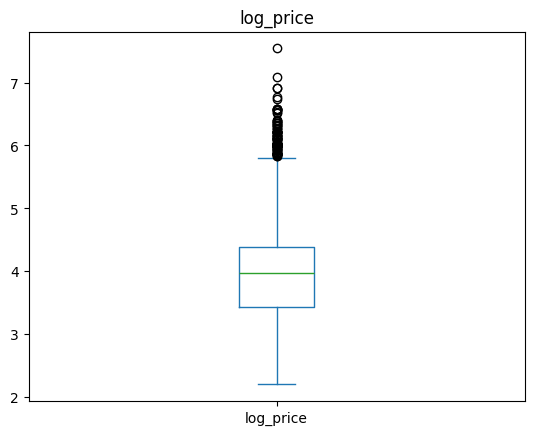

In [47]:
plt.figure()
y_train_reg.plot.box()
plt.title("log_price")
plt.show()


*   *log_minimum_nights* : se observa una cantidad considerable de valores atípicos en la parte superior. Esto indica que existen alojamientos con estancias mínimas extremadamente largas. Además, los datos (la caja) se sitúan entre 0 y 1, lo que equivale a estancias de entre 1 y 3 noches.

*   *log_calculated_host_listings_count* : se observa también gran cantidad de outliers en la parte superior, ya que la gran mayoría de los anfitriones gestionan 1 o 2 propiedades.


*   *log_price* : a diferencia de las variables anteriores, la caja de log_price es mucho más simétrica, confirmando que la transformación logarítmica ha sido exitosa. Pero también se observan numerosos valores atípicos en la parte superior.





La eliminación de outliers se realiza mediante el criterio del rango intercuartílico (IQR). En cada variable se calculan el primer cuartil (Q1), el tercer cuartil (Q3) y el IQR, considerando como outliers aquellos valores que quedan fuera del rango [Q1−1.5⋅IQR,Q3+1.5⋅IQR].

In [48]:
# Outliers en log_minimum_nights
Q1 = X_train_reg['log_minimum_nights'].quantile(0.25)
Q3 = X_train_reg['log_minimum_nights'].quantile(0.75)
IQR = Q3 - Q1

mask_min_nights = (
    (X_train_reg['log_minimum_nights'] >= Q1 - 1.5 * IQR) &
    (X_train_reg['log_minimum_nights'] <= Q3 + 1.5 * IQR)
)

# Outliers en log_calculated_host_listings_count
Q1 = X_train_reg['log_calculated_host_listings_count'].quantile(0.25)
Q3 = X_train_reg['log_calculated_host_listings_count'].quantile(0.75)
IQR = Q3 - Q1

mask_listings = (
    (X_train_reg['log_calculated_host_listings_count'] >= Q1 - 1.5 * IQR) &
    (X_train_reg['log_calculated_host_listings_count'] <= Q3 + 1.5 * IQR)
)

# Outliers en log_price
Q1 = y_train_reg.quantile(0.25)
Q3 = y_train_reg.quantile(0.75)
IQR = Q3 - Q1

mask_price = (
    (y_train_reg >= Q1 - 1.5 * IQR) &
    (y_train_reg <= Q3 + 1.5 * IQR)
)

# Máscara conjunta
mask = mask_min_nights & mask_listings & mask_price

# Eliminación
X_train_reg = X_train_reg.loc[mask]
y_train_reg = y_train_reg.loc[mask]

print(f"Se eliminaron {len(mask) - mask.sum()} observaciones por outliers")


Se eliminaron 855 observaciones por outliers


En total se eliminaron 855 observaciones correspondientes a valores atípicos en las variables *log_minimum_nights*, *log_calculated_host_listings_count* y *log_price*. Esta cantidad representa menos del 10% del total de los datos, por lo que la eliminación es razonable.

**6.2. LinearSVR**

A continuación, creamos un modelo LinearSVR para predecir el precio por noche (*log_price*).

Se introduce el preprocesamiento de las variables y el modelo en un pipeline, aplicando RobustScaler para las variables numéricas y OneHotEncoder para las variables categóricas.

Además, se mantiene el valor por defecto del parámetro C=1 y se realiza un modelo considerando todas las variables y otro eliminando neighbourhood.



*  Con todas las variables independientes


In [52]:
categorical_reg = ['neighbourhood_group', 'neighbourhood', 'room_type']
numeric_reg = ['latitude', 'longitude', 'log_minimum_nights', 'log_number_of_reviews',
                'log_reviews_per_month', 'log_calculated_host_listings_count', 'availability_365']

preprocessor_reg = ColumnTransformer(transformers=[
    ('num', RobustScaler(), numeric_reg),
    ('cat', OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore'), categorical_reg)
])

In [53]:
pipe_linear_svr = Pipeline([
    ('preprocess', preprocessor_reg),
    ('model', LinearSVR(random_state=42,  max_iter=20000))
])

scores_linear_svr = cross_val_score(
    pipe_linear_svr,
    X_train_reg,
    y_train_reg,
    cv=10,
    scoring='r2'
)

print("R2 promedio:", scores_linear_svr.mean())

/usr/local/lib/python3.12/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


R2 promedio: 0.5819112771004292


/usr/local/lib/python3.12/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


En los conjuntos de validación, el 58% de la variabilidad de *log_price* es explicada por el modelo LinearSVR usando todas las variables. El 42% restante corresponde a variabilidad que el modelo no puede explicar. No es un valor muy alto pero puede ser aceptable.



*   Con todas las variables independientes excepto neighbourhood



Veamos cómo cambia el R cuadrado sin considerar la variable neighbourhood:

In [54]:
categorical_reg2 = ['neighbourhood_group', 'room_type']

preprocessor_reg2 = ColumnTransformer(transformers=[
    ('num', RobustScaler(), numeric_reg),
    ('cat', OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore'), categorical_reg2)
])

pipe_linear_svr2 = Pipeline([
    ('preprocess', preprocessor_reg2),
    ('model', LinearSVR(random_state=42,  max_iter=20000))
])

scores_linear_svr2 = cross_val_score(
    pipe_linear_svr2,
    X_train_reg,
    y_train_reg,
    cv=10,
    scoring='r2'
)

print("R2 promedio:", scores_linear_svr2.mean())

R2 promedio: 0.5702963719934873


Al eliminar la variable neighbourhood, el R² promedio disminuye muy poco, a 0.57, indicando que esta variable aporta poca información sobre el precio, es decir, la mayor parte de la variabilidad de los precios sigue siendo explicada por las demás variables.



**6.3. SVR**

Para evaluar si un modelo no lineal puede mejorar la predicción de precios, se crea un modelo SVR.

Se utilizan los valores por defecto para los parámetros y de nuevo se realiza un modelo considerando todas las variables y otro eliminando neighbourhood.



*  Con todas las variables independientes



In [55]:
pipe_svr = Pipeline([
    ('preprocess', preprocessor_reg),
    ('model', SVR())
])

scores_svr = cross_val_score(
    pipe_svr,
    X_train_reg,
    y_train_reg,
    cv=10,
    scoring='r2'
)

print("R2 promedio:", scores_svr.mean())

/usr/local/lib/python3.12/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


R2 promedio: 0.6082358962022889


Al usar un modelo SVR con kernel RBF, el R² promedio aumenta de 0.58 a 0.61 respecto a LinearSVR. Esto indica que capturar relaciones no lineales entre las variables independientes y el precio mejora la capacidad predictiva del modelo, aunque todavía existe una parte de la variabilidad que no es explicada por las variables incluidas.



*   Con todas las variables independientes excepto neighbourhood



In [56]:
pipe_svr2 = Pipeline([
    ('preprocess', preprocessor_reg2),
    ('model', SVR())
])

scores_svr2 = cross_val_score(
    pipe_svr2,
    X_train_reg,
    y_train_reg,
    cv=10,
    scoring='r2'
)

print("R2 promedio:", scores_svr2.mean())

R2 promedio: 0.6059056214912835


Al igual que con LinearSVR, al eliminar la variable neighbourhood, el R² promedio del SVR apenas disminuye de 0.61 a 0.606, lo que indica que esta variable aporta muy poca información adicional en comparación con las demás.

El modelo que muestra mejor capacidad predictiva es el SVR con kernel RBF. Por ello, realizaremos la afinación de sus hiperparámetros para mejorar su desempeño, prescindiendo de la variable neighbourhood, ya que su aportación a la predicción es mínima.

**6.4. Afinación de hiperparámetros del mejor modelo**

En este apartado se realiza la afinación de los hiperparámetros de SVR, concretamente C y gamma, usando el kernel RBF mediante GridSearchCV. Al igual que en clasificación, primero se hace una búsqueda amplia y después una búsqueda más refinada alrededor de los mejores valores encontrados en la anterior búsqueda.

**Primera búsqueda**

In [57]:
param_grid1 = {
    'model__C': np.logspace(-2, 3, 6),
    'model__gamma': np.logspace(-4, 1, 6)
}

grid1 = GridSearchCV(
    pipe_svr2,
    param_grid1,
    cv=3,
    scoring='r2',
    n_jobs=-1
)

grid1.fit(X_train_reg, y_train_reg)

best_C = grid1.best_params_['model__C']
best_gamma = grid1.best_params_['model__gamma']

print("Mejores parámetros:", grid1.best_params_)
print("Mejor R2:", grid1.best_score_)

Mejores parámetros: {'model__C': np.float64(1.0), 'model__gamma': np.float64(0.1)}
Mejor R2: 0.5977945288280077


**Segunda búsqueda**

In [58]:
param_grid2 = {
    'model__C': np.logspace(np.log10(best_C / 5), np.log10(best_C * 5), 5),
    'model__gamma': np.logspace(np.log10(best_gamma / 5), np.log10(best_gamma * 5), 5)
}

grid2 = GridSearchCV(
    pipe_svr2,
    param_grid2,
    cv=3,
    scoring='r2',
    n_jobs=-1
)

grid2.fit(X_train_reg, y_train_reg)

print("Mejores parámetros:", grid2.best_params_)
print("Mejor R2:", grid2.best_score_)

Mejores parámetros: {'model__C': np.float64(2.2360679774997894), 'model__gamma': np.float64(0.1)}
Mejor R2: 0.6006314413292039


La combinación óptima corresponde a C = 2.24 y gamma = 0.1, parámetros que maximizan la capacidad para generalizar a datos no vistos. Con esta configuración, el modelo alcanza un R cuadrado de 0.6.

Para realizar comparaciones consistentes, se redefine el pipeline SVR con 10 particiones de validación cruzada usando estos parámetros óptimos:

In [71]:
pipe_svr3 = Pipeline([
    ('preprocess', preprocessor_reg2),
    ('model', SVR(C=2.24, gamma=0.1))
])

scores_svr3 = cross_val_score(
    pipe_svr3,
    X_train_reg,
    y_train_reg,
    cv=10,
    scoring='r2'
)

print("R2 promedio:", scores_svr3.mean())

R2 promedio: 0.6069736625349329


El R² promedio de SVR con C = 2.24 y gamma = 0.1, es de 0.607 aproximadamente.

**6.5. Evaluación final en el conjunto test**

Evaluamos en test los modelos que no consideran la variable neighbourhood:

In [72]:
# Entrenar los modelos
pipe_linear_svr2.fit(X_train_reg, y_train_reg)
pipe_svr2.fit(X_train_reg, y_train_reg)
pipe_svr3.fit(X_train_reg, y_train_reg)

# Predecir en test
y_pred_linear2 = pipe_linear_svr2.predict(X_test_reg)
y_pred_svr2 = pipe_svr2.predict(X_test_reg)
y_pred_svr3 = pipe_svr3.predict(X_test_reg)

# R2
r2_linear = r2_score(y_test_reg, y_pred_linear2)
r2_svr = r2_score(y_test_reg, y_pred_svr2)
r2_svr2 = r2_score(y_test_reg, y_pred_svr3)

# RMSE
rmse_linear = np.sqrt(mean_squared_error(y_test_reg, y_pred_linear2))
rmse_svr = np.sqrt(mean_squared_error(y_test_reg, y_pred_svr2))
rmse_svr_opt = np.sqrt(mean_squared_error(y_test_reg, y_pred_svr3))

print("Resultados en test:")
print("LinearSVR -> R2:", round(r2_linear, 4), " RMSE:", round(rmse_linear, 4))
print("SVR       -> R2:", round(r2_svr, 4), " RMSE:", round(rmse_svr, 4))
print("SVR afinado -> R2:", round(r2_svr2, 4), " RMSE:", round(rmse_svr_opt, 4))

Resultados en test:
LinearSVR -> R2: 0.4957  RMSE: 0.4953
SVR       -> R2: 0.5158  RMSE: 0.4853
SVR afinado -> R2: 0.5204  RMSE: 0.483


Los resultados confirman el patrón observado en validación cruzada, y muestran que el SVR afinado es el que logra el mejor ajuste, aunque todos los modelos presentan un rendimiento razonable incluso sin considerar la variable neighbourhood.

A continuación, se realiza un gráfico de dispersión comparando los valores reales de la variable objetivo (*log_price*) con las predicciones del modelo en el conjunto de test.

Los puntos cercanos a esta línea son predicciones acertadas, mientras que los puntos alejados representan errores del modelo.



* **LinearSVR**



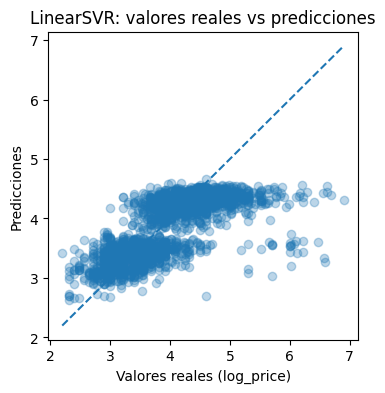

In [77]:
plt.figure(figsize=(4, 4))
plt.scatter(y_test_reg, y_pred_linear2, alpha=0.3)
plt.plot(
    [y_test_reg.min(), y_test_reg.max()],
    [y_test_reg.min(), y_test_reg.max()],
    linestyle='--'
)
plt.xlabel("Valores reales (log_price)")
plt.ylabel("Predicciones")
plt.title("LinearSVR: valores reales vs predicciones")
plt.show()

El gráfico de LinearSVR muestra que el modelo predice correctamente la tendencia general de los precios, pero tiene dificultades en los valores extremos.



*   **SVR**



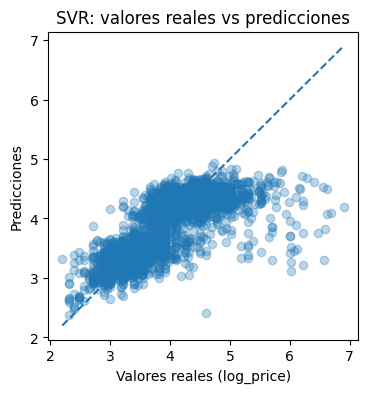

In [78]:
plt.figure(figsize=(4, 4))
plt.scatter(y_test_reg, y_pred_svr2, alpha=0.3)
plt.plot(
    [y_test_reg.min(), y_test_reg.max()],
    [y_test_reg.min(), y_test_reg.max()],
    linestyle='--'
)
plt.xlabel("Valores reales (log_price)")
plt.ylabel("Predicciones")
plt.title("SVR: valores reales vs predicciones")
plt.show()

El gráfico del modelo SVR muestra una mejora significativa respecto al modelo lineal, logrando que las predicciones se ajusten mucho más a la diagonal. Aunque persiste cierta dispersión en los extremos.



*   **SVR afinado**


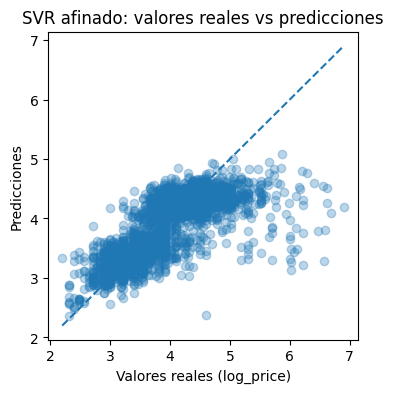

In [79]:
plt.figure(figsize=(4, 4))
plt.scatter(y_test_reg, y_pred_svr3, alpha=0.3)
plt.plot(
    [y_test_reg.min(), y_test_reg.max()],
    [y_test_reg.min(), y_test_reg.max()],
    linestyle='--'
)
plt.xlabel("Valores reales (log_price)")
plt.ylabel("Predicciones")
plt.title("SVR afinado: valores reales vs predicciones")
plt.show()

El gráfico del SVR afinado muestra el mejor ajuste obtenido, con los puntos mucho más concentrados alrededor de la línea diagonal. En comparación con el modelo sin ajuste, se observa una mejora en los precios altos. Sin embargo, todavía le cuesta alcanzar los valores más altos.

**6.6. Conclusiones de los modelos de regresión**

In [80]:
datos = pd.DataFrame({
    "Modelo": ["LinearSVR", "SVR", "SVR afinado"],
    "R2 CV": [0.5703, 0.606, 0.607],
    "R2 Test": [0.4957, 0.5158, 0.5204],
    "RMSE Test": [0.4953, 0.4853, 0.483]
})

tabla_resultados = pd.DataFrame(datos)
display(tabla_resultados)

,Modelo,R2 CV,R2 Test,RMSE Test
0,LinearSVR,0.5703,0.4957,0.4953
1,SVR,0.6060,0.5158,0.4853
2,SVR afinado,0.6070,0.5204,0.4830


En los modelos de regresión evaluados sin considerar la variable neighbourhood, se observa que LinearSVR alcanza un R² de 0.570 en validación cruzada y 0.496 en test, con un RMSE de 0.495, lo que indica que explica aproximadamente la mitad de la variabilidad del precio por noche.

El SVR con kernel RBF mejora ligeramente el desempeño, alcanzando R² de 0.606 en validación y 0.516 en test, con un RMSE de 0.485, mostrando que capturar relaciones no lineales ayuda a predecir mejor los precios.

Tras la afinación de hiperparámetros, el SVR afinado logra el mejor resultado, con R² de 0.607 en validación y 0.520 en test, y un RMSE de 0.483.

**7. CONCLUSIONES**

Se analizaron los datos de Airbnb en Madrid usando modelos SVM para clasificación del tipo de alojamiento y regresión del precio por noche. La exploración de los datos mostró distribuciones sesgadas, outliers y desbalance en room_type, por lo que se aplicaron transformaciones logarítmicas, escalado y manejo de clases desiguales.

En clasificación, LinearSVC alcanzó  un 87% de exactitud, siendo eficaz en las clases mayoritarias pero sin predecir bien la clase minoritaria. SVC con kernel RBF mejoró la detección de clases y, tras afinar los hiperparámetros, el SVC afinado alcanzó 88.5% en validación y 89% en test, mejorando la predicción de las clases mayoritarias.

En regresión, LinearSVR explicó un 57% de la variabilidad en validación y 49.5% en test. SVR con kernel RBF mejoró el desempeño (R² = 0.61 en validación y 0.516 en test) y el SVR afinado logró R² ≈ 0.607 en validación y 0.520 en test con RMSE 0.483. La variable neighbourhood aportó poca información adicional.

En conclusión, tanto en clasificación como en regresión, los modelos no lineales captan mejor las relaciones entre variables, lo que se refleja en la mayor exactitud de SVC afinado y el mejor R² de SVR afinado, mostrando un ajuste más preciso y mejor generalización.